<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


<h1>Extracting and Visualizing Stock Data</h1>
<h2>Description</h2>


Extracting essential data from a dataset and displaying it is a necessary part of data science; therefore individuals can make correct decisions based on the data. In this assignment, you will extract some stock data, you will then display this data in a graph.


<h2>Table of Contents</h2>
<div class="alert alert-block alert-info" style="margin-top: 20px">
    <ul>
        <li>Define a Function that Makes a Graph</li>
        <li>Question 1: Use yfinance to Extract Stock Data</li>
        <li>Question 2: Use Webscraping to Extract Tesla Revenue Data</li>
        <li>Question 3: Use yfinance to Extract Stock Data</li>
        <li>Question 4: Use Webscraping to Extract GME Revenue Data</li>
        <li>Question 5: Plot Tesla Stock Graph</li>
        <li>Question 6: Plot GameStop Stock Graph</li>
    </ul>
<p>
    Estimated Time Needed: <strong>30 min</strong></p>
</div>

<hr>


***Note***:- If you are working Locally using anaconda, please uncomment the following code and execute it.
Use the version as per your python version.


**Configuración del entorno.** Ejecuta esta celda primero: detecta si estás en JupyterLite o en Jupyter normal e instala lo necesario.

In [25]:
# Configuración del entorno: funciona en Jupyter Notebook/Lab local, Google Colab y JupyterLite.
import sys
EN_NAVEGADOR = sys.platform == "emscripten"   # True en JupyterLite (Python Pyodide)

if EN_NAVEGADOR:
    # En JupyterLite no existe "!pip"; se instala con piplite
    import piplite
    for paquete in ["beautifulsoup4", "html5lib", "matplotlib", "pyodide-http", "yfinance"]:
        try:
            await piplite.install(paquete)
            print(f"Instalado: {paquete}")
        except Exception as e:
            print(f"No se pudo instalar {paquete}: {e}")
    try:
        import pyodide_http
        pyodide_http.patch_all()   # permite que requests funcione dentro del navegador
    except Exception as e:
        print("Aviso: no se pudo activar pyodide_http:", e)
else:
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "yfinance", "beautifulsoup4", "html5lib", "matplotlib"], check=False)
    print("Paquetes listos")

Instalado: beautifulsoup4
Instalado: html5lib
Instalado: matplotlib
Instalado: pyodide-http
No se pudo instalar yfinance: Can't find a pure Python 3 wheel for 'curl-cffi>=0.17'.
See: https://pyodide.org/en/stable/usage/faq.html#why-can-t-micropip-find-a-pure-python-wheel-for-a-package
You can use `await micropip.install(..., keep_going=True)` to get a list of all packages with missing wheels.


In [26]:
import pandas as pd
import requests
from bs4 import BeautifulSoup

try:
    import yfinance as yf
    YF_OK = True
except Exception as e:
    YF_OK = False
    print("yfinance no está disponible en este entorno:", e)
    print("Se usarán los archivos TSLA.csv y GME.csv que subas a la misma carpeta del notebook.")

# El navegador no permite cambiar el User-Agent; fuera del navegador sí se envía
HEADERS = {} if EN_NAVEGADOR else {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
                  "(KHTML, like Gecko) Chrome/120.0 Safari/537.36"}


import os, glob

def buscar_csv(archivo):
    """Busca el CSV en la carpeta actual y en el almacenamiento de JupyterLite (/drive), sin importar mayúsculas."""
    carpetas = [os.getcwd(), "/drive", "/home/pyodide", "."]
    candidatos = []
    for carpeta in carpetas:
        candidatos += glob.glob(os.path.join(carpeta, "**", "*.csv"), recursive=True)
    for ruta in candidatos:
        if os.path.basename(ruta).lower() == archivo.lower():
            return ruta
    encontrados = sorted({os.path.basename(r) for r in candidatos})
    raise FileNotFoundError(
        f"No encontré '{archivo}'. CSV visibles para Python: {encontrados or 'ninguno'}. "
        f"Carpeta actual: {os.getcwd()}. Sube el archivo al panel de archivos y renómbralo exactamente '{archivo}'.")


def cargar_csv(archivo):
    """Respaldo para JupyterLite: lee precios históricos descargados de Yahoo Finance o Nasdaq
    y los deja con el mismo formato que devuelve yfinance (índice Date + Open, High, Low, Close, Volume)."""
    df = pd.read_csv(buscar_csv(archivo))
    df.columns = [c.strip() for c in df.columns]
    df = df.rename(columns={"Close/Last": "Close"})
    for col in ["Open", "High", "Low", "Close", "Adj Close", "Volume"]:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col].astype(str).str.replace(r"[$,]", "", regex=True), errors="coerce")
    df["Date"] = pd.to_datetime(df["Date"])
    df = df.dropna(subset=["Close"]).sort_values("Date").set_index("Date")
    columnas = [c for c in ["Open", "High", "Low", "Close", "Volume"] if c in df.columns]
    print(f"{archivo}: {len(df)} filas cargadas ({df.index.min().date()} a {df.index.max().date()})")
    return df[columnas]

yfinance no está disponible en este entorno: No module named 'yfinance'
Se usarán los archivos TSLA.csv y GME.csv que subas a la misma carpeta del notebook.


In Python, you can ignore warnings using the warnings module. You can use the filterwarnings function to filter or ignore specific warning messages or categories.


In [27]:
import warnings
# Ignore all warnings
warnings.filterwarnings("ignore", category=FutureWarning)

## Define Graphing Function


In this section, we define the function `make_graph`. **You don't have to know how the function works, you should only care about the inputs. It takes a dataframe with stock data (dataframe must contain Date and Close columns), a dataframe with revenue data (dataframe must contain Date and Revenue columns), and the name of the stock.**


In [28]:
# The make_graph function has been modified to use Matplotlib for static graphs. Earlier, it used Plotly to generate interactive dashboards, which caused issues when uploading the notebook in the MARK assignment submission.



import matplotlib.pyplot as plt

def make_graph(stock_data, revenue_data, stock):
    stock_data_specific = stock_data[stock_data.Date <= '2021-06-14']
    revenue_data_specific = revenue_data[revenue_data.Date <= '2021-04-30']

    fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

    # Stock price
    axes[0].plot(pd.to_datetime(stock_data_specific.Date), stock_data_specific.Close.astype("float"), label="Share Price", color="blue")
    axes[0].set_ylabel("Price ($US)")
    axes[0].set_title(f"{stock} - Historical Share Price")

    # Revenue
    axes[1].plot(pd.to_datetime(revenue_data_specific.Date), revenue_data_specific.Revenue.astype("float"), label="Revenue", color="green")
    axes[1].set_ylabel("Revenue ($US Millions)")
    axes[1].set_xlabel("Date")
    axes[1].set_title(f"{stock} - Historical Revenue")

    plt.tight_layout()
    plt.show()

Use the make_graph function that we’ve already defined. You’ll need to invoke it in questions 5 and 6 to display the graphs and create the dashboard. 
> **Note: You don’t need to redefine the function for plotting graphs anywhere else in this notebook; just use the existing function.**


## Question 1: Use yfinance to Extract Stock Data


Using the `Ticker` function enter the ticker symbol of the stock we want to extract data on to create a ticker object. The stock is Tesla and its ticker symbol is `TSLA`.


In [29]:
if YF_OK:
    tesla = yf.Ticker("TSLA")

Using the ticker object and the function `history` extract stock information and save it in a dataframe named `tesla_data`. Set the `period` parameter to ` "max" ` so we get information for the maximum amount of time.


In [30]:
tesla_data = tesla.history(period="max") if YF_OK else pd.DataFrame()

if tesla_data.empty:
    # JupyterLite no puede conectarse a Yahoo Finance: se usa el CSV subido a la carpeta del notebook
    tesla_data = cargar_csv("TSLA.csv")

TSLA.csv: 2514 filas cargadas (2016-11-07 a 2026-11-06)


**Reset the index** using the `reset_index(inplace=True)` function on the tesla_data DataFrame and display the first five rows of the `tesla_data` dataframe using the `head` function. Take a screenshot of the results and code from the beginning of Question 1 to the results below.


In [31]:
tesla_data.reset_index(inplace=True)
# Quitar la zona horaria (si la hay) para que make_graph pueda filtrar por fecha sin errores
if tesla_data["Date"].dt.tz is not None:
    tesla_data["Date"] = tesla_data["Date"].dt.tz_localize(None)
tesla_data.head()

,Date,Open,High,Low,Close,Volume
0,2016-11-07,12.9060,12.9527,12.6700,12.8807,57865201
1,2016-11-08,12.9193,13.1660,12.7507,12.9960,48793881
2,2016-11-09,12.4583,12.8000,12.2633,12.6707,122496644
3,2016-11-10,12.7367,12.7740,12.0280,12.3567,101194299
4,2016-11-11,12.2827,12.5920,12.2000,12.5707,59806335


## Question 2: Use Webscraping to Extract Tesla Revenue Data


Use the `requests` library to download the webpage https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/revenue.htm Save the text of the response as a variable named `html_data`.


In [32]:
url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/revenue.htm"
try:
    html_data = requests.get(url, headers=HEADERS, timeout=30).text
except Exception:
    # Respaldo para JupyterLite: descarga con la función fetch del navegador
    from pyodide.http import pyfetch
    respuesta = await pyfetch(url)
    html_data = await respuesta.string()
print(len(html_data), "caracteres descargados")

64779 caracteres descargados


Parse the html data using `beautiful_soup` using parser i.e `html5lib` or `html.parser`.


In [33]:
soup = BeautifulSoup(html_data, "html.parser")

Using `BeautifulSoup` or the `read_html` function extract the table with `Tesla Revenue` and store it into a dataframe named `tesla_revenue`. The dataframe should have columns `Date` and `Revenue`.


<details><summary>Step-by-step instructions</summary>

```

Here are the step-by-step instructions:

1. Create an Empty DataFrame
2. Find the Relevant Table
3. Check for the Tesla Quarterly Revenue Table
4. Iterate Through Rows in the Table Body
5. Extract Data from Columns
6. Append Data to the DataFrame

```
</details>


<details><summary>Click here if you need help locating the table</summary>

```
    
Below is the code to isolate the table, you will now need to loop through the rows and columns like in the previous lab
    
soup.find_all("tbody")[1]
    
If you want to use the read_html function the table is located at index 1

We are focusing on quarterly revenue in the lab.
```

</details>


In [34]:
# La segunda tabla (índice 1) es la de ingresos trimestrales de Tesla
rows = []
for row in soup.find_all("tbody")[1].find_all("tr"):
    cols = row.find_all("td")
    if len(cols) == 2:
        rows.append({"Date": cols[0].text.strip(), "Revenue": cols[1].text.strip()})

tesla_revenue = pd.DataFrame(rows, columns=["Date", "Revenue"])
tesla_revenue.head()

,Date,Revenue
0,2022-09-30,"$21,454"
1,2022-06-30,"$16,934"
2,2022-03-31,"$18,756"
3,2021-12-31,"$17,719"
4,2021-09-30,"$13,757"


Execute the following line to remove the comma and dollar sign from the `Revenue` column. 


In [35]:
tesla_revenue["Revenue"] = tesla_revenue['Revenue'].str.replace(r',|\$',"",regex=True)

Execute the following lines to remove an null or empty strings in the Revenue column.


In [36]:
tesla_revenue.dropna(inplace=True)

tesla_revenue = tesla_revenue[tesla_revenue['Revenue'] != ""]

Display the last 5 row of the `tesla_revenue` dataframe using the `tail` function. Take a screenshot of the results.


In [37]:
tesla_revenue.tail()

,Date,Revenue
48,2010-09-30,31
49,2010-06-30,28
50,2010-03-31,21
52,2009-09-30,46
53,2009-06-30,27


## Question 3: Use yfinance to Extract Stock Data


Using the `Ticker` function enter the ticker symbol of the stock we want to extract data on to create a ticker object. The stock is GameStop and its ticker symbol is `GME`.


In [38]:
if YF_OK:
    gme = yf.Ticker("GME")

Using the ticker object and the function `history` extract stock information and save it in a dataframe named `gme_data`. Set the `period` parameter to ` "max" ` so we get information for the maximum amount of time.


In [39]:
gme_data = gme.history(period="max") if YF_OK else pd.DataFrame()

if gme_data.empty:
    # JupyterLite no puede conectarse a Yahoo Finance: se usa el CSV subido a la carpeta del notebook
    gme_data = cargar_csv("GME.csv")

GME.csv: 2514 filas cargadas (2016-11-07 a 2026-11-06)


**Reset the index** using the `reset_index(inplace=True)` function on the gme_data DataFrame and display the first five rows of the `gme_data` dataframe using the `head` function. Take a screenshot of the results and code from the beginning of Question 3 to the results below.


In [40]:
gme_data.reset_index(inplace=True)
# Quitar la zona horaria (si la hay) para que make_graph pueda filtrar por fecha sin errores
if gme_data["Date"].dt.tz is not None:
    gme_data["Date"] = gme_data["Date"].dt.tz_localize(None)
gme_data.head()

,Date,Open,High,Low,Close,Volume
0,2016-11-07,5.2500,5.3825,5.1875,5.3100,11529080
1,2016-11-08,5.2850,5.3125,5.2150,5.2275,7536184
2,2016-11-09,5.1475,5.4025,5.1253,5.3825,6963132
3,2016-11-10,5.4400,5.6300,5.4275,5.4675,10095280
4,2016-11-11,5.4525,5.5925,5.3750,5.5800,8789412


## Question 4: Use Webscraping to Extract GME Revenue Data


Use the `requests` library to download the webpage https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/stock.html. Save the text of the response as a variable named `html_data_2`


In [41]:
url_2 = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/stock.html"
try:
    html_data_2 = requests.get(url_2, headers=HEADERS, timeout=30).text
except Exception:
    # Respaldo para JupyterLite: descarga con la función fetch del navegador
    from pyodide.http import pyfetch
    respuesta = await pyfetch(url_2)
    html_data_2 = await respuesta.string()
print(len(html_data_2), "caracteres descargados")

88703 caracteres descargados


Parse the html data using `beautiful_soup` using parser i.e `html5lib` or `html.parser`.


In [42]:
soup_2 = BeautifulSoup(html_data_2, "html.parser")

Using `BeautifulSoup` or the `read_html` function extract the table with `GameStop Revenue` and store it into a dataframe named `gme_revenue`. The dataframe should have columns `Date` and `Revenue`. Make sure the comma and dollar sign is removed from the `Revenue` column.


> **Note: Use the method similar to what you did in question 2.**  


<details><summary>Click here if you need help locating the table</summary>

```
    
Below is the code to isolate the table, you will now need to loop through the rows and columns like in the previous lab
    
soup.find_all("tbody")[1]
    
If you want to use the read_html function the table is located at index 1


```

</details>


In [43]:
# La segunda tabla (índice 1) es la de ingresos trimestrales de GameStop
rows = []
for row in soup_2.find_all("tbody")[1].find_all("tr"):
    cols = row.find_all("td")
    if len(cols) == 2:
        rows.append({"Date": cols[0].text.strip(), "Revenue": cols[1].text.strip()})

gme_revenue = pd.DataFrame(rows, columns=["Date", "Revenue"])
gme_revenue.head()

,Date,Revenue
0,2020-04-30,"$1,021"
1,2020-01-31,"$2,194"
2,2019-10-31,"$1,439"
3,2019-07-31,"$1,286"
4,2019-04-30,"$1,548"


Remove the comma and dollar sign, an null or empty strings from the Revenue column.


In [44]:
gme_revenue["Revenue"] = gme_revenue["Revenue"].str.replace(r",|\$", "", regex=True)
gme_revenue.dropna(inplace=True)
gme_revenue = gme_revenue[gme_revenue["Revenue"] != ""]

Display the last five rows of the `gme_revenue` dataframe using the `tail` function. Take a screenshot of the results.


In [45]:
gme_revenue.tail()

,Date,Revenue
57,2006-01-31,1667
58,2005-10-31,534
59,2005-07-31,416
60,2005-04-30,475
61,2005-01-31,709


## Question 5: Plot Tesla Stock Graph


Use the `make_graph` function to graph the Tesla Stock Data, also provide a title for the graph. Note the graph will only show data upto June 2021.


<details><summary>Hint</summary>

```

You just need to invoke the make_graph function with the required parameter to print the graphs.The structure to call the `make_graph` function is `make_graph(tesla_data, tesla_revenue, 'Tesla')`.

```
    
</details>


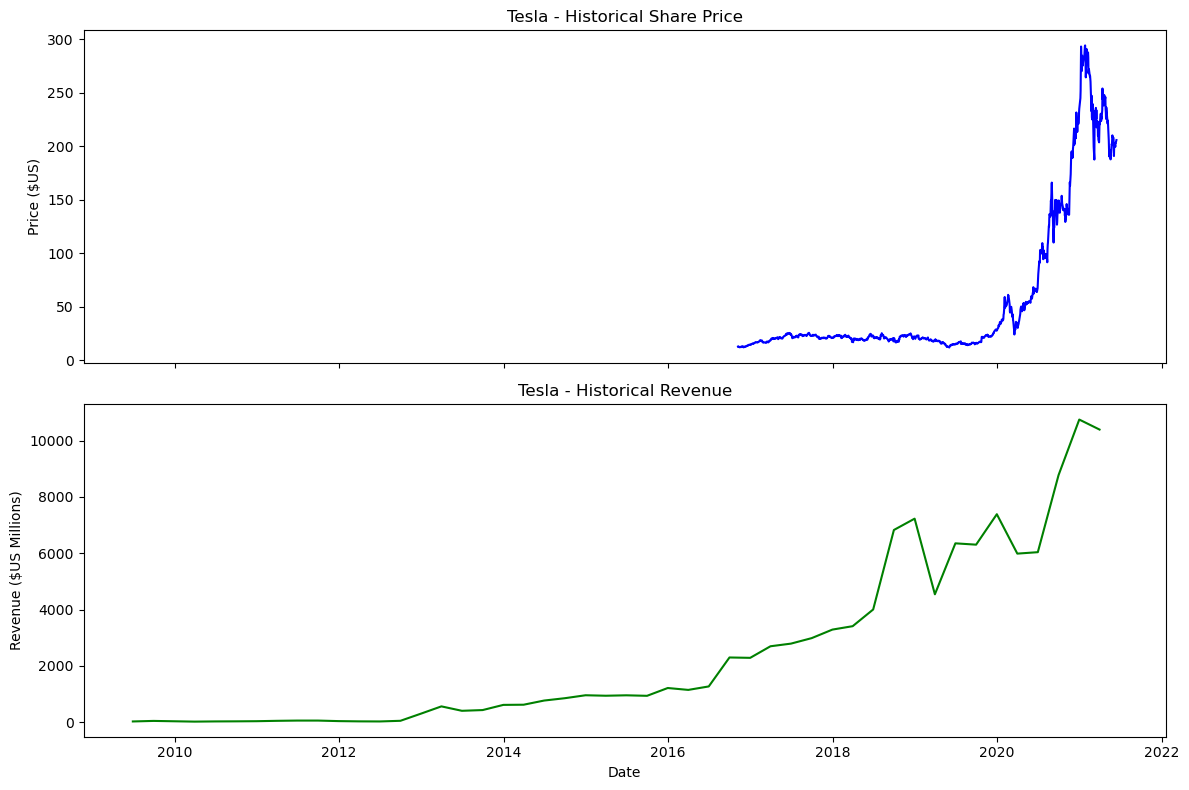

In [46]:
make_graph(tesla_data, tesla_revenue, 'Tesla')

## Question 6: Plot GameStop Stock Graph


Use the `make_graph` function to graph the GameStop Stock Data, also provide a title for the graph. The structure to call the `make_graph` function is `make_graph(gme_data, gme_revenue, 'GameStop')`. Note the graph will only show data upto June 2021.


<details><summary>Hint</summary>

```

You just need to invoke the make_graph function with the required parameter to print the graphs.The structure to call the `make_graph` function is `make_graph(gme_data, gme_revenue, 'GameStop')`

```
    
</details>


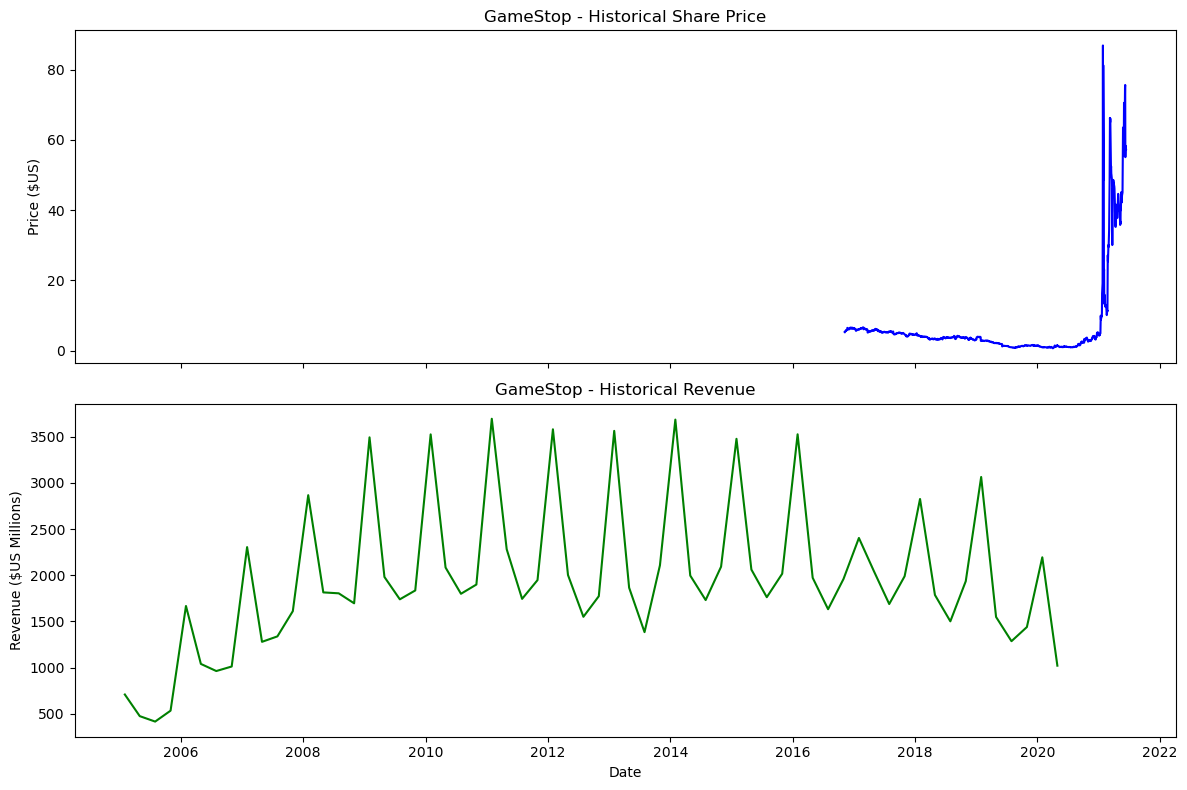

In [47]:
make_graph(gme_data, gme_revenue, 'GameStop')

<h2>About the Authors:</h2> 

<a href="https://www.linkedin.com/in/joseph-s-50398b136/">Joseph Santarcangelo</a> has a PhD in Electrical Engineering, his research focused on using machine learning, signal processing, and computer vision to determine how videos impact human cognition. Joseph has been working for IBM since he completed his PhD.

Azim Hirjani


## Change Log

| Date (YYYY-MM-DD) | Version | Changed By    | Change Description        |
| ----------------- | ------- | ------------- | ------------------------- |
| 2022-02-28        | 1.2     | Lakshmi Holla | Changed the URL of GameStop |
| 2020-11-10        | 1.1     | Malika Singla | Deleted the Optional part |
| 2020-08-27        | 1.0     | Malika Singla | Added lab to GitLab       |

<hr>


Copyright © 2020 IBM Corporation. All rights reserved.
